## Import libraries

In [1]:
# ============================================================
# PROJECT : News Crawling and Clustering
# STEP    : 02 - News Clustering
# SOURCE  : Detik.com
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession
from pyspark.sql.functions import (
    col,
    trim,
    regexp_replace,
    concat_ws,
    size,
    count,
    lower,
    explode,
    monotonically_increasing_id,
    avg,
    desc

)

from pyspark.ml.feature import (
    Tokenizer,
    StopWordsRemover,
    CountVectorizer,
    IDF
)

from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator
from pyspark.ml.functions import vector_to_array
from pymongo import MongoClient, UpdateOne


## Spark configuration

In [2]:
# Configuration input and output paths
INPUT_JSON = "../data/news_data.json"

OUTPUT_DIR = "../outputs"
CLUSTERED_JSON = os.path.join(
    OUTPUT_DIR, "clustered_news.json"
)
CLUSTERED_CSV = os.path.join(
    OUTPUT_DIR, "clustered_news.csv"
)

# Configuration for clustering
RANDOM_SEED = 42
K_VALUES = [2, 3, 4, 5, 6]
NUM_FEATURES = 5000

os.makedirs(OUTPUT_DIR, exist_ok=True)

spark = (
    SparkSession.builder
    .appName("NewsTextClustering")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")

print("Spark version:", spark.version)
print("Input dataset:", INPUT_JSON)

Spark version: 3.5.4
Input dataset: ../data/news_data.json


## Reading a JSON dataset

In [3]:
if not os.path.exists(INPUT_JSON):
    raise FileNotFoundError(
        f"Dataset not found: {INPUT_JSON}. "
        "Run notebook 01_news_crawling.ipynb first."
    )

# JSON produced by the crawliing notebook is in the form of an array of objects, so we need to set multiLine=True
df = spark.read.json(
    INPUT_JSON,
    multiLine=True
)

required_columns = [
    "title",
    "url",
    "source",
    "description",
    "page_number"
]

missing_columns = [
    column_name
    for column_name in required_columns
    if column_name not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Dataset columns are missing: {missing_columns}"
    )

df = df.select(*required_columns)

print("Initial number of articles:", df.count())

df.printSchema()

df.show(
    5,
    truncate=False
)

Initial number of articles: 56
root
 |-- title: string (nullable = true)
 |-- url: string (nullable = true)
 |-- source: string (nullable = true)
 |-- description: string (nullable = true)
 |-- page_number: long (nullable = true)

+--------------------------------------------------------------------------------+----------------------------------------------------------------------------------------------------------------------+---------+--------------------------------------------------------------------------------------------------------------------------------------------------------------+-----------+
|title                                                                           |url                                                                                                                   |source   |description                                                                                                                                                   |page_number|
+--

## Cleaning and validating data

In [4]:
# Deleting data that doesn't have a URL, title, or description
df_clean = (
    df
    .filter(col("url").isNotNull())
    .filter(col("title").isNotNull())
    .filter(col("description").isNotNull())
    .filter(trim(col("url")) != "")
    .filter(trim(col("title")) != "")
    .filter(trim(col("description")) != "")
)

# Deleting duplicates based on article URL
df_clean = df_clean.dropDuplicates(["url"])

# Cleaning whitespace
df_clean = (
    df_clean
    .withColumn(
        "title",
        trim(
            regexp_replace(col("title"), r"\s+", " ")
        )
    )
    .withColumn(
        "description",
        trim(
            regexp_replace(
                col("description"),
                r"\s+",
                " "
            )
        )
    )
)

# Merging title and description to have more complete text information
df_clean = df_clean.withColumn(
    "text",
    concat_ws(
        " ",
        col("title"),
        col("description")
    )
)

total_articles = df_clean.count()

print("Total articles after cleaning:", total_articles)

if total_articles < 3:
    raise ValueError(
        "Dataset is too small to test multiple K values."
    )

df_clean.select(
    "title",
    "description",
    "url"
).show(
    5,
    truncate=False
)

Total articles after cleaning: 56
+-----------------------------------------------------------------------------+----------------------------------------------------------------------------------------------------------------------------------------------------------------+--------------------------------------------------------------------------------------------------------------------+
|title                                                                        |description                                                                                                                                                     |url                                                                                                                 |
+-----------------------------------------------------------------------------+----------------------------------------------------------------------------------------------------------------------------------------------------------------+----------

## Tokenization and stopword removal

In [5]:
indonesian_stopwords = [
    "yang", "dan", "di", "ke", "dari", "untuk",
    "dengan", "pada", "adalah", "itu", "ini",
    "dalam", "karena", "juga", "akan", "telah",
    "sudah", "tidak", "ada", "oleh", "sebagai",
    "atau", "agar", "bagi", "saat", "setelah",
    "sebelum", "hingga", "antara", "lebih", "masih",
    "dapat", "bisa", "menjadi", "tersebut", "ia",
    "dia", "mereka", "kami", "kita", "saya",
    "anda", "nya", "terhadap", "yakni", "yaitu",
    "sejak", "secara", "pun", "para", "namun",
    "tetapi", "maupun", "serta", "bagaimana",
    "mengapa", "apa", "siapa", "kapan", "bukan",
    "belum", "sangat", "hanya", "setiap", "banyak",
    "jadi", "satu", "dua", "tiga", "karna",
    "news", "detik", "com"
]

# Text Tokenization
tokenizer = Tokenizer(
    inputCol="text",
    outputCol="tokens"
)

tokenized = tokenizer.transform(df_clean)

# Deleting stoprewords in Bahasa Indonesia
stopword_remover = StopWordsRemover(
    inputCol="tokens",
    outputCol="filtered_tokens",
    stopWords=indonesian_stopwords,
    caseSensitive=False
)

filtered = stopword_remover.transform(tokenized)

# Deleting articles that don't have any tokens after preprocessing
filtered = filtered.filter(
    size(col("filtered_tokens")) > 0
)

filtered = filtered.cache()

remaining_articles = filtered.count()

print(
    "Total articles after preprocessing:",
    remaining_articles
)

if remaining_articles < 3:
    raise ValueError(
        "Articles with sufficient tokens are too few "
        "for clustering process."
    )

filtered.select(
    "title",
    "filtered_tokens"
).show(
    5,
    truncate=False
)

Total articles after preprocessing: 56
+----------------------------------------------------------------------------+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|title                                                                       |filtered_tokens                                                                                                                                                                                                                         |
+----------------------------------------------------------------------------+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|98 Resolution Network Be

## Creating CountVectorizer and TF-IDF features

In [6]:
# Turning tokens into word frequencies
count_vectorizer = CountVectorizer(
    inputCol="filtered_tokens",
    outputCol="raw_features",
    vocabSize=NUM_FEATURES,
    minDF=1.0
)

cv_model = count_vectorizer.fit(filtered)

tf_data = cv_model.transform(filtered)

print(
    "Total words in vocabulary:",
    len(cv_model.vocabulary)
)

if len(cv_model.vocabulary) == 0:
    raise ValueError(
        "Vocabulary is empty. Please check the text preprocessing steps."
    )

# Calculating TF-IDF
idf = IDF(
    inputCol="raw_features",
    outputCol="tfidf_features"
)

idf_model = idf.fit(tf_data)

tfidf = idf_model.transform(tf_data).cache()

print("Fitur TF-IDF successfully created.")
print("Number of documents:", tfidf.count())

tfidf.select(
    "title",
    "tfidf_features"
).show(
    3,
    truncate=False
)

Total words in vocabulary: 670
Fitur TF-IDF successfully created.
Number of documents: 56
+----------------------------------------------------------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|title                                                                 |tfidf_features                                                                                                                                                                                                                                        

## Testing K values

In [7]:
max_k = min(
    max(K_VALUES),
    remaining_articles - 1
)

candidate_k = [
    k for k in K_VALUES
    if 2 <= k <= max_k
]

if not candidate_k:
    raise ValueError(
        "There is no valid K value for this dataset."
    )

evaluator = ClusteringEvaluator(
    featuresCol="tfidf_features",
    predictionCol="prediction",
    metricName="silhouette",
    distanceMeasure="squaredEuclidean"
)

evaluation_results = []
models = {}

for k in candidate_k:
    print(f"\nRunning K-Means with K={k}")

    kmeans = KMeans(
        k=k,
        seed=RANDOM_SEED,
        featuresCol="tfidf_features",
        predictionCol="prediction",
        maxIter=100,
        tol=1e-4
    )

    model = kmeans.fit(tfidf)

    predictions_k = model.transform(tfidf).cache()

    # Evaluating Silhouette Score
    score = evaluator.evaluate(predictions_k)

    # Article distribution per cluster
    distribution_rows = (
        predictions_k
        .groupBy("prediction")
        .count()
        .collect()
    )

    distribution = {
        int(row["prediction"]): int(row["count"])
        for row in distribution_rows
    }

    evaluation_results.append({
        "k": k,
        "silhouette_score": float(score),
        "cluster_distribution": str(distribution),
        "smallest_cluster": min(distribution.values()),
        "largest_cluster": max(distribution.values())
    })

    models[k] = (model, predictions_k)

    print(f"Silhouette Score: {score:.4f}")
    print("Distribusi cluster:", distribution)

    predictions_k.unpersist()

results_df = pd.DataFrame(evaluation_results)

results_df = results_df.sort_values(
    "silhouette_score",
    ascending=False
).reset_index(drop=True)

print("\nResults of model comparison:")
display(results_df)


Running K-Means with K=2
Silhouette Score: 0.2142
Distribusi cluster: {0: 55, 1: 1}

Running K-Means with K=3
Silhouette Score: 0.1024
Distribusi cluster: {0: 53, 2: 2, 1: 1}

Running K-Means with K=4
Silhouette Score: -0.1668
Distribusi cluster: {0: 53, 3: 1, 2: 1, 1: 1}

Running K-Means with K=5
Silhouette Score: -0.1369
Distribusi cluster: {1: 50, 2: 2, 0: 1, 4: 1, 3: 2}

Running K-Means with K=6
Silhouette Score: -0.1480
Distribusi cluster: {1: 50, 2: 2, 0: 1, 4: 1, 5: 1, 3: 1}

Results of model comparison:


,k,silhouette_score,cluster_distribution,smallest_cluster,largest_cluster
0,2,0.214170,"{0: 55, 1: 1}",1,55
1,3,0.102357,"{0: 53, 2: 2, 1: 1}",1,53
2,5,-0.136943,"{1: 50, 2: 2, 0: 1, 4: 1, 3: 2}",1,50
3,6,-0.147956,"{1: 50, 2: 2, 0: 1, 4: 1, 5: 1, 3: 1}",1,50
4,4,-0.166816,"{0: 53, 3: 1, 2: 1, 1: 1}",1,53


## Choosing a model and evaluating the results

In [8]:
best_k = int(
    results_df.iloc[0]["k"]
)

best_score = float(
    results_df.iloc[0]["silhouette_score"]
)

best_model, _ = models[best_k]

# Remaking the best model prediction
best_predictions = best_model.transform(
    tfidf
).cache()

print("Best candidate K:", best_k)
print(f"Silhouette Score: {best_score:.4f}")

if best_score < 0:
    print(
        "WARNING: Negative Silhouette Score. "
        "The cluster separation isn't good yet."
    )
elif best_score < 0.25:
    print(
        "NOTE: Cluster separation is still relatively weak."
    )
else:
    print(
        "Internal evaluation shows "
        "better cluster separation, but the cluster contents "
        "still need to be checked."
    )

best_predictions.select(
    "title",
    "url",
    "prediction"
).show(
    10,
    truncate=False
)

Best candidate K: 2
Silhouette Score: 0.2142
NOTE: Cluster separation is still relatively weak.
+----------------------------------------------------------------------------+-------------------------------------------------------------------------------------------------------------------+----------+
|title                                                                       |url                                                                                                                |prediction|
+----------------------------------------------------------------------------+-------------------------------------------------------------------------------------------------------------------+----------+
|98 Resolution Network Beberkan Gerak Nyata 2 Tahun Prabowo-Gibran           |https://news.detik.com/berita/d-8717470/98-resolution-network-beberkan-gerak-nyata-2-tahun-prabowo-gibran          |0         |
|DEN Menghadap Prabowo, Lapor Temuan soal Kehadiran Siswa Penerima MBG       |ht

## Cluster distribution visualization

+----------+--------------+
|prediction|total_articles|
+----------+--------------+
|         0|            55|
|         1|             1|
+----------+--------------+



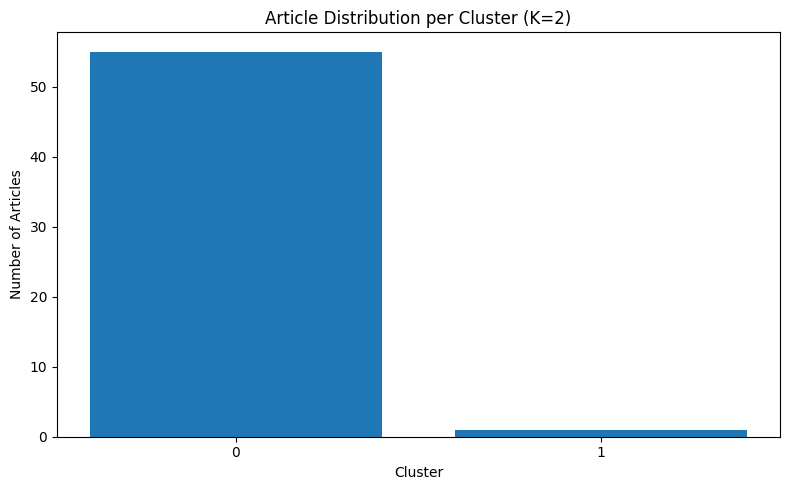

In [9]:
cluster_counts = (
    best_predictions
    .groupBy("prediction")
    .agg(
        count("*").alias("total_articles")
    )
    .orderBy("prediction")
)

cluster_counts.show()

cluster_pd = cluster_counts.toPandas()

plt.figure(figsize=(8, 5))

plt.bar(
    cluster_pd["prediction"].astype(str),
    cluster_pd["total_articles"]
)

plt.title(
    f"Article Distribution per Cluster (K={best_k})"
)
plt.xlabel("Cluster")
plt.ylabel("Number of Articles")
plt.tight_layout()
plt.show()

## Checking the title and content of each cluster

In [10]:
for cluster_id in range(best_k):
    print(f"\n{'=' * 70}")
    print(f"CLUSTER {cluster_id}")
    print("=" * 70)

    cluster_articles = (
        best_predictions
        .filter(col("prediction") == cluster_id)
        .select(
            "title",
            "description",
            "url"
        )
    )

    print(
        "Jumlah artikel:",
        cluster_articles.count()
    )

    cluster_articles.show(
        20,
        truncate=100
    )


CLUSTER 0
Jumlah artikel: 55
+--------------------------------------------------------------------------------+----------------------------------------------------------------------------------------------------+----------------------------------------------------------------------------------------------------+
|                                                                           title|                                                                                         description|                                                                                                 url|
+--------------------------------------------------------------------------------+----------------------------------------------------------------------------------------------------+----------------------------------------------------------------------------------------------------+
|               98 Resolution Network Beberkan Gerak Nyata 2 Tahun Prabowo-Gibran|Relawan Prabowo-Gibran memaparkan

## Looking at the most prominent word in each cluster

In [11]:
# Converting TF-IDF vector into an array
feature_data = (
    best_predictions
    .select(
        "prediction",
        vector_to_array(
            col("tfidf_features")
        ).alias("features")
    )
)

# Creating one row per feature index
exploded_features = (
    feature_data
    .select(
        "prediction",
        explode(
            col("features")
        ).alias("weight")
    )
)

In [12]:
# Note:
# explode alone does not preserve feature indices.
# To get the exact words, use the following
# word counting method per cluster.


cluster_tokens = (
    best_predictions
    .select(
        "prediction",
        explode(
            col("filtered_tokens")
        ).alias("word")
    )
    .filter(col("word") != "")
)

top_words = (
    cluster_tokens
    .groupBy(
        "prediction",
        "word"
    )
    .count()
    .orderBy(
        "prediction",
        desc("count")
    )
)

for cluster_id in range(best_k):
    print(f"\nFrequently appearing words — Cluster {cluster_id}")

    (
        top_words
        .filter(col("prediction") == cluster_id)
        .select("word", "count")
        .show(15, truncate=False)
    )


Frequently appearing words — Cluster 0
+------------+-----+
|word        |count|
+------------+-----+
|prabowo     |91   |
|tahun       |34   |
|presiden    |33   |
|pemerintahan|22   |
|2           |22   |
|kabinet     |22   |
|subianto    |21   |
|sidang      |17   |
|indonesia   |15   |
|capaian     |11   |
|tak         |8    |
|ketua       |8    |
|besar       |8    |
|gibran      |7    |
|prabowo,    |7    |
+------------+-----+
only showing top 15 rows


Frequently appearing words — Cluster 1
+-----------+-----+
|word       |count|
+-----------+-----+
|energi     |3    |
|nilai      |2    |
|mekeng     |2    |
|perkuat    |2    |
|kebijakan  |2    |
|kemandirian|2    |
|prabowo    |2    |
|kedaulatan |1    |
|dukung     |1    |
|melchias   |1    |
|komisi     |1    |
|nasional,  |1    |
|gibran     |1    |
|ekonomi    |1    |
|ketua      |1    |
+-----------+-----+
only showing top 15 rows



## Saving clustering results to JSON and CSV

In [13]:
result_df = best_predictions.select(
    "title",
    "url",
    "source",
    "description",
    "page_number",
    "prediction"
)

result_pd = result_df.toPandas()

result_pd["prediction"] = (
    result_pd["prediction"].astype(int)
)

# Save as a JSON in the form of an object array
result_pd.to_json(
    CLUSTERED_JSON,
    orient="records",
    force_ascii=False,
    indent=4
)

# Save as CSV
result_pd.to_csv(
    CLUSTERED_CSV,
    index=False,
    encoding="utf-8-sig"
)

print("The clustering results have been successfully saved.")
print("Number of articles:", len(result_pd))
print("JSON:", CLUSTERED_JSON)
print("CSV:", CLUSTERED_CSV)

The clustering results have been successfully saved.
Number of articles: 56
JSON: ../outputs\clustered_news.json
CSV: ../outputs\clustered_news.csv


## Saving the results to MongoDB

In [14]:
MONGO_URI = os.getenv(
    "MONGO_URI",
    "mongodb://localhost:27017/"
)

DATABASE_NAME = "big_data"
COLLECTION_NAME = "uts"

client = MongoClient(
    MONGO_URI,
    serverSelectionTimeoutMS=5000
)

client.admin.command("ping")

db = client[DATABASE_NAME]
collection = db[COLLECTION_NAME]

operations = []

for row in result_pd.to_dict(orient="records"):
    url = str(row["url"]).strip()

    if not url:
        continue

    operations.append(
        UpdateOne(
            {"url": url},
            {
                "$set": {
                    "title": row["title"],
                    "source": row["source"],
                    "description": row["description"],
                    "page_number": row["page_number"],
                    "cluster": int(row["prediction"])
                }
            },
            upsert=True
        )
    )

if operations:
    result = collection.bulk_write(
        operations,
        ordered=False
    )

    print("The clustering results are saved in MongoDB.")
    print("New documents:", result.upserted_count)
    print("Updated documents:", result.modified_count)
    print("Matching documents:", result.matched_count)

print(
    "Total documents in MongoDB:",
    collection.count_documents({})
)

The clustering results are saved in MongoDB.
New documents: 1
Updated documents: 55
Matching documents: 55
Total documents in MongoDB: 57


## Final verification

In [15]:
print("Cluster distribution in the final results:")

for row in (
    best_predictions
    .groupBy("prediction")
    .count()
    .orderBy("prediction")
    .collect()
):
    print(
        f"Cluster {row['prediction']}: "
        f"{row['count']} artikel"
    )

print("\nExample MongoDB documents:")

for doc in collection.find(
    {},
    {
        "_id": 0,
        "title": 1,
        "url": 1,
        "cluster": 1
    }
).limit(5):
    print(doc)

best_predictions.unpersist()
filtered.unpersist()
tfidf.unpersist()

print("\nProcess clustering completed.")

Cluster distribution in the final results:
Cluster 0: 55 artikel
Cluster 1: 1 artikel

Example MongoDB documents:
{'url': 'https://news.detik.com/berita/d-8716355/hut-ke-62-golkar-bogor-serukan-dukung-presiden-prabowo-2-periode', 'cluster': 0, 'title': 'HUT ke-62, Golkar Bogor Serukan Dukung Presiden Prabowo 2 Periode'}
{'url': 'https://news.detik.com/berita/d-8716459/luhut-ungkap-rencana-prabowo-hilirisasi-kratom-dan-kemenyan-pada-2027', 'cluster': 0, 'title': 'Luhut Ungkap Rencana Prabowo Hilirisasi Kratom dan Kemenyan pada 2027'}
{'url': 'https://news.detik.com/berita/d-8716474/den-menghadap-prabowo-lapor-temuan-soal-kehadiran-siswa-penerima-mbg', 'cluster': 0, 'title': 'DEN Menghadap Prabowo, Lapor Temuan soal Kehadiran Siswa Penerima MBG'}
{'url': 'https://news.detik.com/berita/d-8716476/prabowo-bakal-luncurkan-perlinsos-digital-bansos-berubah-jadi-transfer-tunai', 'cluster': 0, 'title': 'Prabowo Bakal Luncurkan Perlinsos Digital, Bansos Berubah Jadi Transfer Tunai'}
{'url': 'http